In [1]:
from main import *

In [8]:
def run_experiment(
        n=1000, 
        d=50, 
        prop_noised=0.1, 
        b_noise_scale=0.2, 
        teacher_noise_scale=0.1,
        x0_scale=50,
        iters=5000,
        seed=1
    ):
    # Generate system
    rng = np.random.default_rng(seed=seed)
    n_noised = int(n * prop_noised)
    A, x, b = get_system(rng, n, d)

    noised_indices = rng.choice(n, size=n_noised, replace=False)
    b_noised = b
    b_noised[noised_indices] += rng.normal(scale=b_noise_scale, size=n_noised)

    x_teacher = x + rng.normal(size=d, scale=teacher_noise_scale)

    x0 = rng.normal(scale=x0_scale, size=d)

    common_params = dict(
        x0=x0,
        A=A,
        b=b_noised,
        x_sol=x,
        batch_size=n,
        maxiter=iters
    )

    sols = [
        MillerOpt(**common_params, teacher=x_teacher, noised_indices=noised_indices),
        RandomizedKaczmarz(**common_params),
    ]

    for sol in sols:
        sol.solve()

    comparison = Comparison(sols)
    comparison.plot_residuals(
        title=f"Comparing Kaczmarz convergence\n(batch size {common_params["batch_size"]}, noise std {b_noise_scale})",
        logx=False,
        logy=True
    )

    time_bounds = np.array(sols[0].diagnostics["time bounds"])

    plt.plot(time_bounds[:, 0], time_bounds[:, 1], color="tab:green", label="diff eq bound", lw=1)
    plt.axhline(sols[0].diagnostics["tb_floor"], label=f"diff eq bound floor", ls="--", color="tab:green", lw=1)

    # plt.plot(sols[0].diagnostics["bounds"], color="tab:red", label="OG bound")
    iter_range = np.arange(iters)
    e0 = sols[0].scores[0]
    og_floor = sols[0].diagnostics["b_floor"]
    plt.plot(iter_range + 1, (1 - sols[0].alpha / 2)**iter_range * (e0 - og_floor) + og_floor, color="tab:red", label="OG bound", lw=1)
    plt.axhline(og_floor, color="tab:red", ls="--", label="OG bound floor", lw=1)

    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

    print(f"alpha: {sols[0].alpha}")
    print(f"beta:  {sols[0].beta}")
    print(f"gamma: {sols[0].gamma}")

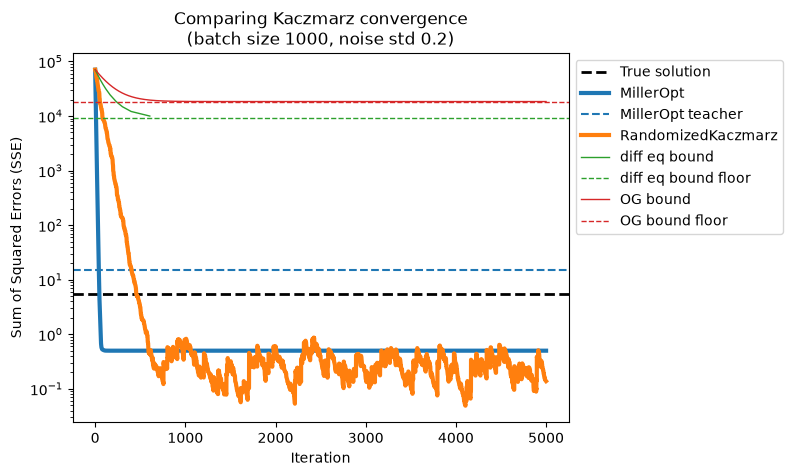

alpha: 0.012495345983451986
beta:  1.1980561218332744
gamma: 0.36012237769080185


In [9]:
run_experiment()